# Hidden Markov Model (HMM) Fixed-Lag Smoothing Study Guide
This notebook provides a complete implementation of **Fixed-Lag Smoothing** in a Hidden Markov Model (HMM), based on the classical Umbrella world example (Russell & Norvig, Chapter 14). It details step-by-step filtering, direct backward verification, and matrix updates to maintain high numerical stability.

## Step 1: Libraries & Parameter Definition
Here we define our transition matrix $T$ and emission diagnostics $O$ as per standard formulations:
- **$T$ (Transition Matrix):** Probability of weather staying the same is $0.7$.
- **$O$ (Emission/Observation Matrix):** Probability of bringing an umbrella given it rains ($0.9$) vs clean weather ($0.2$).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# define HMM parameters
T = np.array([[0.7, 0.3], [0.3, 0.7]])#rows represent today's state and columns represent yesterday's state.
#Prob(Xt/Xt-1)
o = {
    1: np.diag([0.9, 0.2]),  # Umbrella seen #0.9,0.1 Rainy, 0.2,0.8 not rainy
    0: np.diag([0.1, 0.8])   # No umbrella seen
}#prob(Ut/Xt)
N, d = 20, 3 #NO OF DAYS AND LAG
rng = np.random.default_rng(12)

- 0=RAINY, NOT UMBRELLA
- 1=NOT RAINY,UMBRELLA

-  IN T: 0.7 IS THE PROBABILITY OF RAINY TODAY GIVEN YESTERDAY RAINED. WHERE T WAS COLUMN AND T+1 IS THE ROW.
- IN O: 1 IS UMBRELLA : 0.9 IS THE PROBABILITY OF YESTERDAY RAINED GIVEN UMBRELLA SEEN

## Step 2: Simulating Hidden Weather States and Observations
We walk forward randomly starting from a 50/50 prior state probability to generate our true synthetic data series.

In [ ]:
hidden = []#to store states in 0 and 1. 0 means rainy and 1 means not rainy,
observations = []#Variable that stores the umbrella observations.1 means an umbrella is seen and 0 means no umbrella
state = rng.choice(2, p=[0.5, 0.5]) #initially weselect a weather for day 1
print('state of day-1',state)
for i in range(N): # Generates numbers from 0 to N-1
    state = rng.choice(2, p=T[state])#T[0 or 1]=prob of True or False of rain today given yesterday rained
    umbrella = int(rng.random() < [0.9, 0.2][state])#int-convert true or false into 1 or 0 . rng.random()-geneartaes number bet 0 and 1
    #state=t means it takes 0.9 else 0.2
    hidden.append(state)# the list containing actual weather state
    observations.append(umbrella)
print(hidden)
print('Observations generated:', observations)

state of day-1 0
[1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1]
Observations generated: [1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]


## Step 3: Forward Filtering Execution
Calculates $P(X_t \mid e_{1:t})$ sequentially across the timeline via forward message steps.

In [ ]:
def filter_step(f, e):
    f = o[e] @ T.T @ f#o[1] is the matrix of umbrella seen
    return f / f.sum() #f is the list containing proba of o is 1 and o is 0.

f = np.array([0.5, 0.5])# inital forward prob
filtered = []#to store prob
#filtered = [[0.9, 0.1],[0.95, 0.05],[0.7, 0.3]]
for obs in observations:#for each obesrvation weare going to find ots forwad probability:thatis P(Xt/et)

    f = filter_step(f, obs)#we are using copy because we use this current f value for nextforward prob
    filtered.append(f.copy())
filtered = np.array(filtered)#(20, 2)
print(filtered)

[[0.81818182 0.18181818]
 [0.88335704 0.11664296]
 [0.89452728 0.10547272]
 [0.89637976 0.10362024]
 [0.89668528 0.10331472]
 [0.89673562 0.10326438]
 [0.89674391 0.10325609]
 [0.89674528 0.10325472]
 [0.19435707 0.80564293]
 [0.73202825 0.26797175]
 [0.15396413 0.84603587]
 [0.71820776 0.28179224]
 [0.15101063 0.84898937]
 [0.06580118 0.93419882]
 [0.68550828 0.31449172]
 [0.85852575 0.14147425]
 [0.89034541 0.10965459]
 [0.89568829 0.10431171]
 [0.89657129 0.10342871]
 [0.1943086  0.8056914 ]]


## Step 4: Fixed-Lag Smoothing Algorithm with Matrix Verification
We implement incremental window adjustments while tracking mathematical variance matrix verification errors.

In [ ]:
# FIXED-LAG SMOOTHING (1-DAY LAG)

smoothed = []

for k in range(N):
    t = min(k + d, N - 1)
    b = np.ones(2)

    for i in range(t, k, -1):
        b = T @ o[observations[i]] @ b

    s = filtered[k] * b#Combine forward and backward information
    s = s / s.sum()
    smoothed.append(s)

smoothed = np.array(smoothed)

print("Day   Rainy   Not Rainy")
for k in range(N):
    print(k + 1, round(smoothed[k][0], 4),round(smoothed[k][1], 4))

Day   Rainy   Not Rainy
1 0.8964 0.1036
2 0.9357 0.0643
3 0.9422 0.0578
4 0.9433 0.0567
5 0.9435 0.0565
6 0.9403 0.0597
7 0.9259 0.0741
8 0.8295 0.1705
9 0.2577 0.7423
10 0.6049 0.3951
11 0.1966 0.8034
12 0.5536 0.4464
13 0.0969 0.9031
14 0.1193 0.8807
15 0.8073 0.1927
16 0.921 0.079
17 0.9365 0.0635
18 0.9226 0.0774
19 0.82 0.18
20 0.1943 0.8057


## Step 5: Visualizing States and Error Bounds
Plotting true state profiles vs filtering distributions alongside verification matrix errors.

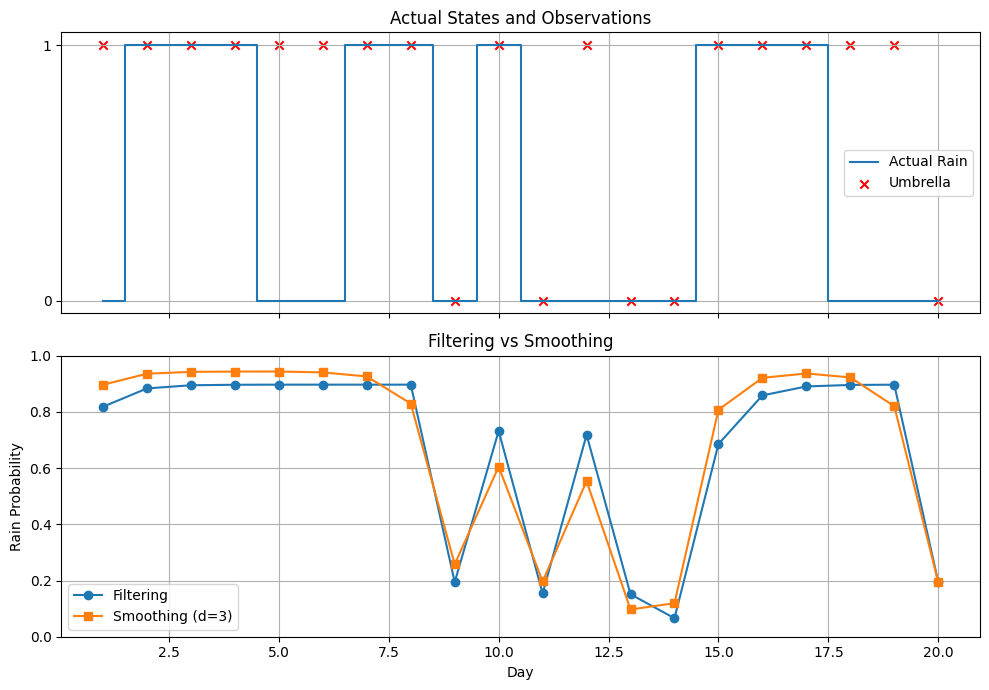

In [ ]:

days = np.arange(1, N + 1)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)#sharex=True: both graphs use the same x-axis, representing days.

# Graph 1: Actual states and observations
ax[0].step(days, 1 - np.array(hidden), where='mid', label='Actual Rain')
ax[0].scatter(days, observations, color='red', marker='x', label='Umbrella')
ax[0].set_title('Actual States and Observations')
ax[0].set_yticks([0, 1])
ax[0].grid()
ax[0].legend()

# Graph 2: Filtering and smoothing
ax[1].plot(days, filtered[:, 0], 'o-', label='Filtering')# is the marker 'o' for shape '-' for line
ax[1].plot(days, smoothed[:, 0], 's-', label=f'Smoothing (d={d})')
ax[1].set_title('Filtering vs Smoothing')
ax[1].set_xlabel('Day')
ax[1].set_ylabel('Rain Probability')
ax[1].set_ylim(0, 1)
ax[1].grid()
ax[1].legend()

plt.tight_layout()
plt.show()


# Steps

1. Import libraries

NumPy and Matplotlib


2. Define parameters

Transition matrix T, observation matrix O, N, d


3. Generate data

Hidden weather and umbrella observations


4. Filtering

Estimate hidden weather using forward information


5. Fixed-Lag Smoothing

Combine forward and backward information


6. Print and plot results

Compare filtering and smoothing probabilities